# Un motor de cartera conciliado con sus anclas analíticas y un tamaño y potencia honestos para la estimación de la correlación

**Pregunta:** ¿Devuelve el motor de cartera los números que existen fuera de él (una integral, la fórmula IRB, formas cerradas, un vector de prueba publicado), y con qué frecuencia se equivoca su prueba de correlación cuando la verdad es conocida?

- **Nivel:** 4, métodos propuestos
- **Requisitos previos:** los notebooks 01 a 07 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este notebook puedes:

- enunciar la afirmación que demuestra este notebook, hasta donde llega su evidencia, y decir qué no afirma;
- contrastar el motor de cartera con cuatro anclas que no vienen del propio motor: la integral de la densidad de la cartera grande, la fórmula de capital IRB escrita con SciPy, la probabilidad y la varianza de forma cerrada de CreditRisk+, y el vector de prueba publicado de la granularidad;
- reproducir hasta ocho dígitos un peldaño de Monte Carlo versionado con el motor publicado, y decir por qué eso es una afirmación más fuerte que coincidir dentro de un error estándar;
- ver el estimador de correlación del motor recuperado frente a una verdad conocida, con su sesgo, error y cobertura, en la grilla del simulador versionada;
- verificar en vivo una celda de esa grilla, y leer el tamaño y la potencia medidos de la prueba de correlación con sus errores;
- decir en qué descansa la afirmación de ausencia, con su fecha, y dónde se detiene.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import integrate, stats

# El cuaderno está tres carpetas por debajo de la raíz del repositorio
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

# Nombres de las luces de validación
LIGHTS = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cuatro archivos versionados del caso C10 (propietario: este repositorio; las tasas de pérdida detrás de los ajustes vienen de la tabla `chgallsa` de la Reserva Federal, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, dominio público, clase de licencia `mirror-allowed`):

- `commercial-industrial.json`: la cartera ilustrativa de 1.120 nombres (construida, nunca la de un banco), la escalera versionada con sus semillas y tamaños de bloque, y el peldaño CreditRisk+;
- `credit-cards.json`: el ajuste y la referencia IRB de la cartera de tarjetas de crédito, usados para el ancla IRB porque la clase minorista renovable tiene correlación fija y ningún ajuste por vencimiento;
- `grid-22.json` y `grid-40.json`: la grilla del simulador, con `truth_status` `synthetic-known-truth`: fracciones de incumplimiento anuales de una cartera grande sorteadas con una PD conocida de 2% y doce correlaciones conocidas, 400 réplicas por celda, series de 22 y 40 años.

La celda siguiente los carga e imprime el estado de verdad de cada uno, que dice si una comparación es contra resultados reales o contra una verdad conocida.

In [2]:
# Cargar los cuatro artefactos e imprimir el estado de verdad de cada uno
read = lambda name: json.loads((ROOT / "data" / "derived" / "C10" / f"{name}.json").read_text(encoding="utf-8"))
ci, cards, grid22, grid40 = read("commercial-industrial"), read("credit-cards"), read("grid-22"), read("grid-40")
TRUTH = {"real-outcomes": "resultados reales", "synthetic-known-truth": "sintética, verdad conocida"}

for name, doc in (("commercial-industrial", ci), ("credit-cards", cards), ("grid-22", grid22), ("grid-40", grid40)):
    print(f"{name:22s} {TRUTH[doc['provenance']['truth_status']]}")

print("calculado con riskvalidation", {d["provenance"]["riskvalidation_version"] for d in (ci, cards, grid22, grid40)})
out = ci["outputs"]
book = out["portfolio"]
pd_hat = out["fit"]["maximum_likelihood"]["pd"]["estimate"]
rho_hat = out["fit"]["maximum_likelihood"]["rho"]["estimate"]
rungs = {r["id"]: r for r in out["rungs"]}
print("cartera:", book["n_names"], "nombres")

commercial-industrial  resultados reales
credit-cards           resultados reales
grid-22                sintética, verdad conocida
grid-40                sintética, verdad conocida
calculado con riskvalidation {'1.0.1'}
cartera: 1120 nombres


## Método

Un motor sin referencia abierta con la cual compararse solo puede contrastarse con cosas que existen fuera de él. Este notebook usa tres tipos, cada uno demostrado abajo:

1. **Anclas analíticas**: formas cerradas y valores publicados que el código del propio motor no calcula. Pasos 1 a 4.
2. **Su propia salida versionada, regenerada**: un peldaño de Monte Carlo que el motor publicado debe reproducir exactamente, porque el generador tiene semilla. Paso 5.
3. **Verdad conocida**: un simulador que sortea datos con una correlación conocida, de modo que el error de un estimador se mide en vez de suponerse. Pasos 6 y 7.

### Paso 1: la distribución de la cartera grande frente a la integral de su densidad

La función de distribución y la densidad del notebook 01 son dos funciones del motor. Si están bien, la integral de la densidad de 0 a $x$ es la función de distribución en $x$. La integral la calcula la cuadratura adaptativa de SciPy, que no usa ninguna de las dos formas cerradas.

In [3]:
# Integrar la densidad del motor con la cuadratura de SciPy y compararla con la función de distribución del motor
from riskvalidation.engines.vasicek import lhp_cdf, lhp_pdf

points = np.array([0.002, 0.005, 0.01, 0.02, 0.035, 0.05, 0.07])
density = lambda t: float(lhp_pdf(t, pd_hat, rho_hat))
areas = np.array([integrate.quad(density, 0.0, x, limit=200)[0] for x in points])
cdf = np.array([float(lhp_cdf(x, pd_hat, rho_hat)) for x in points])

print(f"{'x':>7s} {'integral de la densidad':>34s} {'función de distribución':>30s} {'diferencia':>12s}")
for x, area, value in zip(points, areas, cdf):
    print(f"{x:7.3f} {area:34.12f} {value:30.12f} {area - value:12.1e}")

      x            integral de la densidad        función de distribución   diferencia
  0.002                     0.046571310489                 0.046571310492     -2.8e-12
  0.005                     0.301630749213                 0.301630749213     -2.2e-13
  0.010                     0.668927037945                 0.668927037945     -2.2e-13
  0.020                     0.930865477961                 0.930865477961     -2.2e-13
  0.035                     0.992015590416                 0.992015590420     -4.3e-12
  0.050                     0.998856665187                 0.998856665187     -7.9e-13
  0.070                     0.999891570323                 0.999891570328     -4.3e-12


La celda siguiente dibuja la función de distribución con las integrales como marcas, y el tamaño de su diferencia en un eje logarítmico.

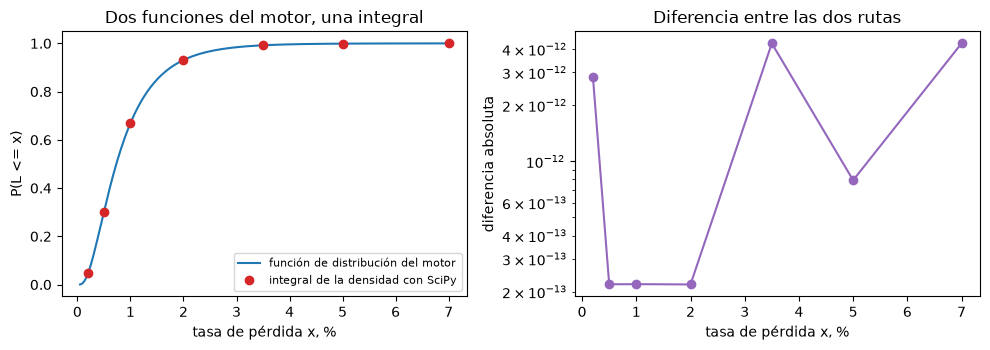

In [4]:
# Dibujar la función de distribución contra la integral de la densidad, y su diferencia
grid = np.linspace(0.0005, 0.07, 300)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
curve = [float(lhp_cdf(x, pd_hat, rho_hat)) for x in grid]
left.plot(100 * grid, curve, color="tab:blue", label="función de distribución del motor")
left.plot(100 * points, areas, "o", color="tab:red", label="integral de la densidad con SciPy")
left.set_xlabel("tasa de pérdida x, %")
left.set_ylabel("P(L <= x)")
left.set_title("Dos funciones del motor, una integral")
left.legend(fontsize=8)
right.semilogy(100 * points, np.abs(areas - cdf), "o-", color="tab:purple")
right.set_xlabel("tasa de pérdida x, %")
right.set_ylabel("diferencia absoluta")
right.set_title("Diferencia entre las dos rutas")
fig.tight_layout()
plt.show()

A la izquierda las marcas rojas, calculadas integrando la densidad con la cuadratura adaptativa de SciPy, caen exactamente sobre la función de distribución azul que el motor calcula en forma cerrada. A la derecha la diferencia es menor que 1e-12 en todos los puntos, que es la exactitud de la cuadratura y no la del motor. La comprobación es un ancla porque la integral no usa ninguna de las dos formas cerradas: si la densidad tuviera una constante equivocada o la función de distribución un error de signo, las marcas saldrían de la curva. Es también solo una condición necesaria, pues un par de funciones equivocadas de forma compatible igual pasaría, y no dice nada sobre si la PD y la correlación ajustadas describen alguna cartera real.

### Paso 2: el capital IRB frente a la fórmula escrita con SciPy

El requerimiento de capital IRB de Basilea para una exposición de PD y LGD dadas es el capital al 99,9% de la cartera grande con la correlación regulatoria $R$ (BCBS, 2005, https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf; Basel Framework CRE31, https://www.bis.org/basel_framework/chapter/CRE/31.htm). Para una exposición minorista renovable, que tiene una correlación fija $R=0{,}04$ y ningún ajuste por vencimiento, es

$$K=\mathrm{LGD}\left[\Phi\!\left(\frac{\Phi^{-1}(\mathrm{PD})+\sqrt{R}\,\Phi^{-1}(0.999)}{\sqrt{1-R}}\right)-\mathrm{PD}\right]$$

La celda siguiente la evalúa con la distribución normal de SciPy en la PD ajustada de la cartera de tarjetas de crédito, y la compara con dos respuestas del motor: `capital_requirement` del módulo IRB y el capital de la cartera grande `lhp_measures` con la misma correlación.

In [5]:
# Evaluar la fórmula IRB con SciPy y compararla con el módulo IRB y el capital de la cartera grande
from riskvalidation.portfolio.portfolio import lhp_measures
from riskvalidation.regulatory.irb import capital_requirement

c_out = cards["outputs"]
pd_cards = c_out["fit"]["maximum_likelihood"]["pd"]["estimate"]
reference = c_out["irb_reference"]
lgd, corr = 0.45, reference["irb_correlation"]

threshold = (stats.norm.ppf(pd_cards) + math.sqrt(corr) * stats.norm.ppf(0.999)) / math.sqrt(1 - corr)
k_scipy = lgd * (stats.norm.cdf(threshold) - pd_cards)
k_module = float(capital_requirement(reference["asset_class"], pd_cards, lgd, regime="basel3").k)
k_lhp = lhp_measures(1.0, lgd, pd_cards, corr, (0.999,))[0].ec
print("clase de activos:", reference["asset_class"], "| PD:", round(pd_cards, 6), "| R:", corr, "| LGD:", lgd)
print(f"K fórmula con SciPy  {k_scipy:.12f}")
print(f"K módulo IRB        {k_module:.12f}   diferencia {k_module - k_scipy:.1e}")
print(f"K cartera grande    {k_lhp:.12f}   diferencia {k_lhp - k_scipy:.1e}")

clase de activos: qrre | PD: 0.042281 | R: 0.04 | LGD: 0.45
K fórmula con SciPy  0.039169914547
K módulo IRB        0.039169914547   diferencia 0.0e+00
K cartera grande    0.039169914547   diferencia 0.0e+00


### Paso 3: CreditRisk+ frente a sus formas cerradas

La recursión de CreditRisk+ del notebook 04 calcula toda la distribución de la pérdida en unidades. Dos propiedades del modelo se conocen en forma cerrada desde su función generadora, así que anclan la recursión sin una segunda implementación de ella. Con un sector, sin peso idiosincrático y varianza Gamma $\sigma^2$, la probabilidad de ninguna pérdida es $P(X=0)=(1+\sigma^2\mu)^{-1/\sigma^2}$ con $\mu=\sum_ip_i$ (Haaf, Reiss y Schoenmakers, 2004, https://doi.org/10.21314/jor.2004.097), y, condicionando en el factor Gamma $S$ (media 1, varianza $\sigma^2$), la media y la varianza de la pérdida en unidades son

$$E[X]=\sum_i\nu_ip_i,\qquad \mathrm{Var}(X)=\sum_i\nu_i^2p_i+\sigma^2\Big(\sum_i\nu_ip_i\Big)^2$$

(el primer término es la varianza de Poisson dado $S$, el segundo la varianza de la media condicional; es una derivación del modelo, no una fórmula citada). La celda siguiente corre la recursión estable en la cartera comercial y compara la media y la varianza de su función de probabilidad con estas.

In [6]:
# Correr la recursión estable y comparar P(X = 0), la media y la varianza con las formas cerradas
from riskvalidation.portfolio import creditrisk_plus as cr

crp = rungs["c4-creditrisk-plus"]
sigma2 = next(p["value"] for p in crp["parameters"] if p["name"] == "sigma2")
loss_unit = next(p["value"] for p in crp["parameters"] if p["name"] == "loss_unit")
n_max = int(next(d["value"] for d in crp["diagnostics"] if d["name"] == "n_max"))
ead = np.concatenate([np.full(g["n_names"], g["ead_each"]) for g in book["groups"]])
pd_names = np.concatenate([np.full(g["n_names"], g["pd"]) for g in book["groups"]])
units = np.rint(ead * book["lgd_mean"] / loss_unit).astype(int)
inp = cr.CreditRiskPlusInput(
    nu=units, pd=pd_names, w0=np.zeros(ead.size), weights=np.ones((ead.size, 1)),
    sigma2=np.array([sigma2]), loss_unit=loss_unit, currency=book["currency"])
pmf = cr.pmf_stable(inp, n_max)

n = np.arange(pmf.size)
mean_pmf = float((n * pmf).sum())
var_pmf = float(((n - mean_pmf) ** 2 * pmf).sum())
mu = float(pd_names.sum())
mean_closed = float((units * pd_names).sum())
var_closed = float((units ** 2 * pd_names).sum() + sigma2 * mean_closed ** 2)
print("masa fuera de la grilla:", f"{1 - pmf.sum():.1e}")
print(f"P(X = 0)  recursión {pmf[0]:.12e} | forma cerrada {(1 + sigma2 * mu) ** (-1 / sigma2):.12e}")
print(f"media      recursión {mean_pmf:.6f} | forma cerrada {mean_closed:.6f}")
print(f"varianza   recursión {var_pmf:.4f} | forma cerrada {var_closed:.4f}")
print("brecha relativa de la varianza:", f"{abs(var_pmf - var_closed) / var_closed:.1e}")

masa fuera de la grilla: 2.7e-13
P(X = 0)  recursión 1.546187529854e-02 | forma cerrada 1.546187529854e-02
media      recursión 409.720505 | forma cerrada 409.720505
varianza   recursión 208626.6484 | forma cerrada 208626.6484
brecha relativa de la varianza: 5.5e-11


### Paso 4: el vector de prueba de granularidad del artículo

Gordy y Lutkebohmert (2013, https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf) imprimen un número que cualquiera que implemente su ajuste puede reproducir: $\delta=4{,}83$ con $\xi=0{,}25$ y $q=0{,}999$. La investigación lo leyó directamente del artículo. El motor calcula $\delta=(\alpha_q-1)(\xi+(1-\xi)/\alpha_q)$ a partir del cuantil de una distribución Gamma. La segunda identidad es la que implica la fórmula del artículo: para $n$ nombres idénticos el ajuste es proporcional a $1/n$, así que $\mathrm{GA}\times n$ no se mueve. La celda siguiente reproduce el vector y comprueba la identidad.

In [7]:
# Calcular el vector de prueba del artículo y comprobar que GA por n es constante para nombres idénticos
from riskvalidation.portfolio import granularity as gr

gran = out["granularity"]
delta = gr.delta(gran["xi"], 0.999)
PUBLISHED_DELTA = 4.83
print("delta (xi = 0.25, q = 0.999):", round(delta, 4), "| publicado:", PUBLISHED_DELTA)
print("el motor coincide en los dígitos impresos:", "sí" if round(delta, 2) == PUBLISHED_DELTA else "no")

k_names = float(capital_requirement("corporate", pd_hat, 0.45, regime="basel3", maturity=2.5).k)
products = []
for n_names in (10, 100, 1000, 10_000):
    ones = np.ones(n_names)
    result = gr.granularity_adjustment(
        ones / n_names, k_names * ones, pd_hat * ones, 0.45 * ones, gran["gamma"], gran["xi"], 0.999)
    products.append(result.ga * n_names)
    print(f"n = {n_names:6d} | GA = {result.ga:.8f} | GA x n = {result.ga * n_names:.8f}")
print("mayor dispersión relativa de GA x n:", f"{(max(products) - min(products)) / max(products):.1e}")

delta (xi = 0.25, q = 0.999): 4.8336 | publicado: 4.83
el motor coincide en los dígitos impresos: sí
n =     10 | GA = 0.12076364 | GA x n = 1.20763644
n =    100 | GA = 0.01207636 | GA x n = 1.20763644
n =   1000 | GA = 0.00120764 | GA x n = 1.20763644
n =  10000 | GA = 0.00012076 | GA x n = 1.20763644
mayor dispersión relativa de GA x n: 7.7e-15


## Comparación

La práctica que supera este notebook es la que la investigación registró para los motores de crédito de cartera. Las fórmulas están en la literatura y son aquello con lo que se contrasta un motor: el límite de la cartera grande y la fórmula IRB (Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8; BCBS, 2005), la función generadora de CreditRisk+ y su recursión estable (Haaf, Reiss y Schoenmakers, 2004), y el ajuste por granularidad con su vector de prueba (Gordy y Lutkebohmert, 2013). La investigación (dossier persistido 04, sección H.8) registra las implementaciones disponibles al 2026-10-04: los paquetes de CRAN CreditMetrics y crp.CSFP están archivados, GCPM 1.2.2 (CRAN, 2016) es antiguo y GPL-2, el repositorio portfolioAnalytics de Open Risk es GPL-2.0, y existen repositorios educativos pequeños (uno en Julia, MIT). Concluyó que **no se encontró una implementación en Python mantenida y con licencia permisiva de CreditMetrics ni de CreditRisk+**, y que por eso un motor debe validarse contra anclas analíticas y no contra una biblioteca sin mantenimiento. Eso es un enunciado de la práctica y de sus límites: el dossier buscó en CRAN y GitHub estas dos familias de modelos en esa fecha, y nada aquí amplía la búsqueda. Para la validación de un modelo de capital económico el dossier (05, sección G.5) prescribe verificar que la asignación suma el total y pruebas de sensibilidad, y anota que una prueba binomial con pocos años tiene poca potencia.

## Evidencia

**La afirmación, para el motor de cartera.** Contraste entrega un motor de cartera de cópulas y CreditRisk+ (y un catálogo de cinco pruebas de validación de cartera) con licencia permisiva, y lo contrasta con anclas que existen fuera de él. Es una afirmación de ausencia acompañada de evidencia: la ausencia es la del dossier, con fecha 2026-10-04 y acotada como en la sección anterior; la evidencia es lo que muestran los pasos de este notebook y un lector puede abrir:

- las filas versionadas y las formas cerradas de los Pasos 1 a 4, reproducidas aquí;
- el peldaño de cópula gaussiana versionado, regenerado hasta ocho dígitos en el Paso 5;
- las filas de tamaño, potencia y cobertura de la grilla del simulador, `data/derived/C10/grid-22.json` y `grid-40.json`, leídas en los Pasos 6 y 7.

**Lo que no se afirma.** La afirmación no es que el motor sea igual a una implementación de referencia, porque la investigación no encontró ninguna con la cual comparar. No es que el motor esté libre de defectos: sus anclas son condiciones necesarias. No extiende la ausencia más allá de CRAN y GitHub al 2026-10-04 (la afirmación del SDD nombra los otros dos componentes, las pruebas del BCE y el motor IRRBB, que demuestran sus propios temas). El muestreador por importancia t de Student es una brecha que el motor registra y no oculta. Y el tamaño y la potencia medidos del estimador de correlación de abajo son evidencia sobre un estimador en un generador, no la afirmación general de que toda prueba del producto tenga su tamaño y potencia medidos.

El Paso 5 regenera el peldaño de cópula gaussiana versionado con el motor publicado. La escalera se calculó con el motor 0.7.0 y el motor instalado es el 0.8.1, y el peldaño se sorteó con un generador con semilla y un tamaño de bloque fijo, así que un motor fiel debe devolver la misma muestra. La corrida usa los 1.000.000 de escenarios del peldaño versionado, porque la igualdad hasta ocho dígitos es el punto (toma alrededor de medio minuto y es la única celda del tema con el tamaño versionado). La celda siguiente la repite y compara VaR, ES y sus errores estándar, dígito a dígito, con los valores versionados.

In [8]:
# Regenerar el peldaño de cópula gaussiana del caso con el motor publicado y compararlo dígito a dígito
from riskvalidation.portfolio import copula
from riskvalidation.portfolio import portfolio as pf

committed = rungs["c2-gaussian-1f"]
sim = committed["simulation"]
one = pf.portfolio_from_groups(book["groups"], book["currency"], book["lgd_gamma"], one_factor=True)
sample = copula.simulate_gaussian(one, sim["n_scenarios"], sim["seed"], sim["chunk_size"])
rerun = pf.measures_from_sample(sample.losses, (0.99, 0.999), pf.expected_loss(one))

relative = []
for m, c in zip(rerun, committed["measures"]):
    pairs = ((m.var, c["var"]), (m.es, c["es"]), (m.var_se, c["var_se"]), (m.es_se, c["es_se"]))
    relative.extend(abs(mine - theirs) / theirs for mine, theirs in pairs)
print("escenarios:", sim["n_scenarios"], "| semilla:", sim["seed"], "| bloque:", sim["chunk_size"])
print("mayor diferencia relativa entre los ocho valores:", f"{max(relative):.1e}")

escenarios: 1000000 | semilla: 4001 | bloque: 16741
mayor diferencia relativa entre los ocho valores: 2.9e-09


### Paso 6: el estimador de correlación frente a una verdad conocida

La grilla del simulador es el propio estimador del motor contrastado con una verdad que los datos no pueden ocultar. Cada celda sortea 400 series de fracciones de incumplimiento anuales con una correlación conocida, ajusta los dos estimadores del notebook 02, y registra la estimación media, el **sesgo** (la estimación media menos el valor conocido), el error cuadrático medio y la **cobertura** del intervalo nominal de 95%, la parte de las réplicas cuyo intervalo contiene la correlación verdadera. Un intervalo bien calibrado tiene cobertura cercana a 0,95. La celda siguiente dibuja el sesgo, la raíz del error cuadrático medio y la cobertura de ambos estimadores contra la correlación conocida, para la grilla de 22 y la de 40 años, a partir de los `cells` versionados.

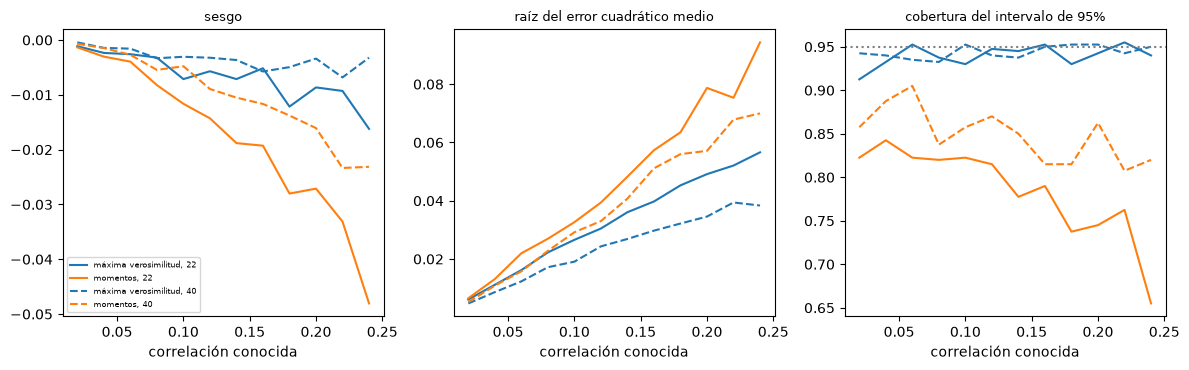

In [9]:
# Dibujar el sesgo, el error y la cobertura de ambos estimadores contra la correlación conocida
estimators = (
    ("maximum-likelihood", "tab:blue", "máxima verosimilitud"),
    ("moments", "tab:orange", "momentos"),
)
measures = (
    ("bias", "sesgo"),
    ("rmse", "raíz del error cuadrático medio"),
    ("coverage", "cobertura del intervalo de 95%"),
)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for years, grid_k, style in ((22, grid22, "-"), (40, grid40, "--")):
    cells = grid_k["outputs"]["cells"]
    rho_known = np.array([c["known_rho"] for c in cells])
    for name, color, label in estimators:
        picked = [next(e for e in c["estimators"] if e["estimator"] == name) for c in cells]
        for ax, (field, _) in zip(axes, measures):
            ax.plot(rho_known, [e[field] for e in picked], style, color=color, label=f"{label}, {years}")
for ax, (_, title) in zip(axes, measures):
    ax.set_xlabel("correlación conocida")
    ax.set_title(title, fontsize=9)
axes[2].axhline(0.95, color="gray", linestyle=":")
axes[0].legend(fontsize=6)
fig.tight_layout()
plt.show()

A la izquierda, el sesgo: el estimador de máxima verosimilitud (azul) se mantiene cerca de cero y se vuelve algo negativo al crecer la correlación verdadera, mientras el estimador de momentos (naranja) cae mucho más abajo de la verdad, con 22 años igual que con 40. Al centro, el error: crece con la correlación para ambos estimadores y es sistemáticamente mayor para momentos, y las curvas de 40 años (discontinuas) quedan bajo las de 22. A la derecha, la cobertura del intervalo nominal de 95%: el azul se mantiene cerca de la línea punteada de 0,95, el naranja cae bien por debajo, a cerca de dos tercios en la correlación más alta. Un validador que lea los tres paneles aprende no solo que el estimador tiene sesgo sino cuánto, dónde importa, y que el intervalo asociado al estimador de momentos no es confiable. La grilla es sintética con una verdad conocida, así que estas son propiedades de los estimadores en este generador.

In [10]:
# Imprimir el sesgo y la cobertura de ambos estimadores en tres correlaciones conocidas
failed = sum(c["n_failed"] for g in (grid22, grid40) for c in g["outputs"]["cells"])
print("réplicas que no se pudieron ajustar en ambas grillas:", failed)
print(f"{'años':>6s} {'rho conocida':>12s} {'estimador':>20s} {'sesgo':>8s} {'cobertura':>9s}")
for years, grid_k in ((22, grid22), (40, grid40)):
    for cell in grid_k["outputs"]["cells"]:
        if round(cell["known_rho"], 2) not in (0.02, 0.12, 0.24):
            continue
        for e in cell["estimators"]:
            print(f"{years:6d} {cell['known_rho']:12.2f} {e['estimator']:>20s} {e['bias']:8.4f} {e['coverage']:9.3f}")

réplicas que no se pudieron ajustar en ambas grillas: 0
  años rho conocida            estimador    sesgo cobertura
    22         0.02   maximum-likelihood  -0.0011     0.912
    22         0.02              moments  -0.0013     0.823
    22         0.12   maximum-likelihood  -0.0057     0.948
    22         0.12              moments  -0.0143     0.815
    22         0.24   maximum-likelihood  -0.0162     0.940
    22         0.24              moments  -0.0481     0.655
    40         0.02   maximum-likelihood  -0.0004     0.943
    40         0.02              moments  -0.0007     0.858
    40         0.12   maximum-likelihood  -0.0032     0.940
    40         0.12              moments  -0.0089     0.870
    40         0.24   maximum-likelihood  -0.0032     0.950
    40         0.24              moments  -0.0231     0.820


### Paso 7: una verificación en vivo de una celda, y el tamaño y la potencia de la prueba

La grilla versionada le tomó horas al flujo de datos, así que no la repetimos. Verificamos una celda, la de tamaño, con un número menor de réplicas sorteadas aquí desde la definición del modelo: 22 años de $x_t=p(z_t)$ con $z_t\sim N(0,1)$, la PD verdadera de la grilla (2%) y la correlación verdadera 0,12, luego el ajuste de máxima verosimilitud del motor y el intervalo de perfil del notebook 02. La prueba de H0: $\rho=0{,}12$ rechaza cuando 0,12 queda fuera del intervalo, así que la tasa de rechazo en el valor verdadero es el tamaño, y la parte de intervalos que contienen 0,12 es la cobertura. Con 100 réplicas el error de Monte Carlo es grande, así que el resultado se lee con su intervalo de Wilson (Wilson, 1927, https://doi.org/10.1080/01621459.1927.10502953) y se pone junto a las tasas versionadas de la grilla de 400 réplicas, cuyas filas vienen de `correlation_size_power` del motor.

In [11]:
# Verificar en vivo la celda de tamaño con 100 réplicas
from riskvalidation.engines.vasicek import conditional_pd
from riskvalidation.portfolio.asrf_fit import fit_ml, profile_interval
from riskvalidation.validation.portfolio import correlation_size_power

generator = grid22["outputs"]["generator"]
true_rho, true_pd = 0.12, generator["known_pd"]
years_n, null_rho = generator["series_length_years"], generator["null_rho"]
rng = np.random.default_rng(20261021)
rejected, estimates = [], []
for _ in range(100):
    rates = np.asarray(conditional_pd(true_pd, true_rho, rng.standard_normal(years_n)))
    fitted = fit_ml(rates)
    low, high = profile_interval(rates, 0.95)["rho"]
    rejected.append(not (low <= null_rho <= high))
    estimates.append(fitted.rho)

flags = np.array(rejected)
live = correlation_size_power(flags, true_rho, null_rho, alpha=generator["alpha"], estimator="maximum-likelihood")
print("en vivo, 100 réplicas: tasa de rechazo (tamaño)", round(live.metric, 3))
print("error", round(live.extras["se"], 3), "| Wilson", round(live.extras["ci_low"], 3), end=" ")
print("-", round(live.extras["ci_high"], 3))
print("estimación media:", round(float(np.mean(estimates)), 4))
for years, grid_k in ((22, grid22), (40, grid40)):
    for row in grid_k["tests"]:
        if row["extras"]["role"] == "size":
            x = row["extras"]
            head = f"grilla {years}, {x['estimator']:18s}: tamaño {row['metric']:.4f}"
            print(head, f"| Wilson {x['ci_low']:.3f} - {x['ci_high']:.3f}")

en vivo, 100 réplicas: tasa de rechazo (tamaño) 0.08
error 0.027 | Wilson 0.041 - 0.15
estimación media: 0.1193
grilla 22, maximum-likelihood: tamaño 0.0525 | Wilson 0.035 - 0.079
grilla 22, moments           : tamaño 0.1850 | Wilson 0.150 - 0.226
grilla 40, maximum-likelihood: tamaño 0.0600 | Wilson 0.041 - 0.088
grilla 40, moments           : tamaño 0.1300 | Wilson 0.101 - 0.167


La última figura pone el tamaño y la potencia versionados en una imagen para el estimador de máxima verosimilitud: la tasa de rechazo frente a la correlación conocida con 22 y con 40 años, con el intervalo de Wilson de cada tasa, el nivel nominal y la puerta de potencia de 80%. Es la respuesta, en este generador, a la pregunta que un validador hace de cualquier prueba: con qué frecuencia rechaza cuando no debe, y con qué frecuencia no rechaza cuando debe.

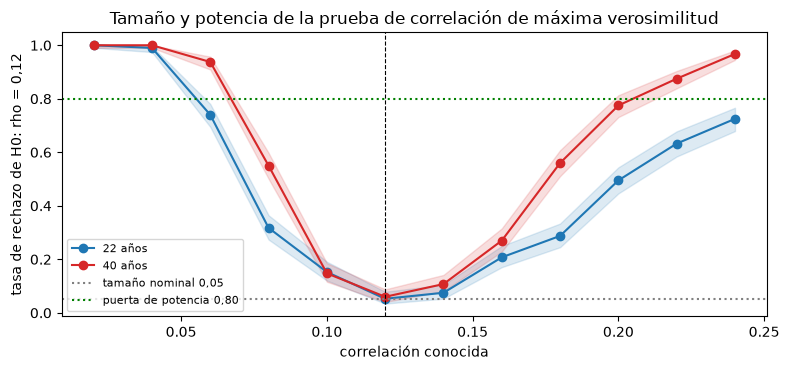

In [12]:
# Dibujar el tamaño y la potencia de la prueba de máxima verosimilitud con 22 y 40 años y sus intervalos de Wilson
fig, ax = plt.subplots(figsize=(8, 3.8))
for (years, grid_k), color in zip(((22, grid22), (40, grid40)), ("tab:blue", "tab:red")):
    rows = [r for r in grid_k["tests"] if r["extras"]["estimator"] == "maximum-likelihood"]
    rho_known = np.array([r["extras"]["known_rho"] for r in rows])
    ax.plot(rho_known, [r["extras"]["rate"] for r in rows], marker="o", color=color, label=f"{years} años")
    band = ([r["extras"]["ci_low"] for r in rows], [r["extras"]["ci_high"] for r in rows])
    ax.fill_between(rho_known, band[0], band[1], color=color, alpha=0.15)
ax.axhline(0.05, color="gray", linestyle=":", label="tamaño nominal 0,05")
ax.axhline(0.80, color="green", linestyle=":", label="puerta de potencia 0,80")
ax.axvline(0.12, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("correlación conocida")
ax.set_ylabel("tasa de rechazo de H0: rho = 0,12")
ax.set_title("Tamaño y potencia de la prueba de correlación de máxima verosimilitud")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La curva azul, 22 años, está cerca del 5% nominal en la nula y luego sube despacio: rechaza una correlación de 0,10 solo el 15% de las veces y una de 0,14 solo el 7,5%, de modo que la prueba no distingue a las vecinas de 0,12 de 0,12, y nunca llega a la puerta de 80% sobre la nula con este largo (72,5% con 0,24). La curva roja, 40 años, es más alta a ambos lados y cruza la puerta entre 0,20 y 0,22. Las bandas son los intervalos de Wilson de 400 réplicas, y muestran que las tasas cerca de la nula se conocen solo con unos pocos puntos. Es la respuesta, en este generador, a la pregunta que un validador hace a cualquier prueba: con qué frecuencia rechaza cuando no debe, y con qué frecuencia no rechaza cuando debe.

## Resultados

**Respuesta:** sí, el motor devuelve los números que existen fuera de él: la integral de su densidad es igual a su función de distribución con diferencia menor que 4,3e-12, el capital IRB 0,039169914547 es igual a la fórmula escrita con SciPy (diferencia 0,0e+00), la probabilidad de ninguna pérdida de CreditRisk+, 1,546187529854e-02, y la varianza, 208626,6484, coinciden con sus formas cerradas (brecha relativa 5,5e-11), $\delta=4{,}8336$ coincide con el 4,83 publicado, y el peldaño de cópula con semilla se regenera hasta una diferencia relativa de 2,9e-09; frente a una verdad conocida su prueba de correlación de máxima verosimilitud rechaza una correlación verdadera el 5,25% de las veces con 22 años frente a un 5% nominal, y su intervalo cubre 0,948 con una correlación de 0,12 donde el de momentos cubre 0,815.

- **Paso 1, las dos funciones del motor coinciden por una tercera ruta.** La integral de la densidad del motor de 0 a $x$, calculada con la cuadratura de SciPy, es igual a la función de distribución del motor hasta 2,2e-13 con x = 0,005, 0,01 y 0,02, hasta 7,9e-13 con 0,05 y hasta a lo más 4,3e-12 en los otros tres puntos, que es el propio error de la cuadratura. Un error en la densidad o en la función de distribución se vería aquí.
- **Paso 2, el capital IRB coincide con la fórmula hasta el último dígito, y la razón limita la comprobación.** Para la cartera de tarjetas de crédito (clase qrre, PD 0,042281, R = 0,04, LGD 0,45) la fórmula escrita con SciPy da K = 0,039169914547, y el módulo IRB y el capital de la cartera grande devuelven el mismo valor con una diferencia de 0,0e+00. Los dígitos son idénticos porque todos llaman a la misma función de distribución normal de SciPy: la comprobación sostiene la fórmula y el cableado del motor, no la distribución normal de SciPy.
- **Paso 3, CreditRisk+ coincide con sus formas cerradas.** La probabilidad de ninguna pérdida de la recursión, 1,546187529854e-02, es igual a $(1+\sigma^2\mu)^{-1/\sigma^2}$ hasta doce dígitos. Su media, 409,720505 unidades de pérdida, es igual a $\sum\nu_ip_i$, y su varianza, 208.626,6484, es igual a la forma cerrada con una brecha relativa de 5,5e-11, con 2,7e-13 de masa de probabilidad fuera de la grilla. La varianza involucra todas las probabilidades de la recursión, así que es una comprobación exigente de toda la distribución, no de una entrada.
- **Paso 4, el vector de prueba publicado se cumple, y el ajuste escala como dice la teoría.** $\delta=4{,}8336$ con $\xi=0{,}25$ y $q=0{,}999$ es igual al 4,83 impreso en el artículo hasta los dígitos impresos. Para nombres idénticos GA por $n$ es 1,20763644 con 10, 100, 1.000 y 10.000 nombres, con una dispersión relativa de 7,7e-15.
- **Paso 5, el motor publicado regenera hasta ocho dígitos un peldaño de Monte Carlo versionado.** Con la semilla 4001, el tamaño de bloque 16741 y un millón de escenarios del caso, la mayor diferencia relativa entre el VaR, el déficit esperado y los dos errores estándar al 99% y al 99,9% es 2,9e-09, el redondeo del archivo versionado. El peldaño se calculó con una versión anterior del motor, así que esto es reproducibilidad entre dos versiones de un método estocástico con semilla, una afirmación más fuerte que coincidir dentro de un error estándar: cualquier cambio en el muestreador, en los bloques o en los estimadores movería los dígitos. No muestra que el muestreador sea correcto, solo que es el mismo.
- **Paso 6, frente a una verdad conocida el estimador de máxima verosimilitud es casi insesgado y su intervalo casi calibrado.** Con 22 años su sesgo es -0,0011 con una correlación verdadera de 0,02, -0,0057 con 0,12 y -0,0162 con 0,24, cerca de 5% a 7% bajo, y la cobertura de su intervalo nominal de 95% es 0,912, 0,948 y 0,940. El estimador de momentos tiene más sesgo (-0,0143 con 0,12 y -0,0481 con 0,24, 12% y 20% bajo) y cubre solo 0,823, 0,815 y 0,655. Con 40 años la cobertura de máxima verosimilitud es 0,943, 0,940 y 0,950, y la de momentos 0,858, 0,870 y 0,820. Ninguna réplica falló en el ajuste en ninguna celda de las dos grillas. Un validador que lea un intervalo del estimador de momentos no debe leerlo como un intervalo de 95%.
- **Paso 7, la verificación en vivo concuerda con la grilla versionada, con el ruido esperable.** Con 100 réplicas con la correlación verdadera 0,12 la tasa de rechazo en vivo es 0,08 (error 0,027, intervalo de Wilson 0,041 a 0,15) y la estimación media 0,1193, frente a 0,0525 (Wilson 0,035 a 0,079) de la grilla de 400 réplicas. La grilla da a la prueba de máxima verosimilitud un tamaño de 0,0525 con 22 años y 0,0600 con 40, ambos verdes, y a la prueba de momentos 0,1850 y 0,1300, ambos rojos.
- **La figura de tamaño y potencia.** La prueba de máxima verosimilitud con 22 años tiene poca potencia cerca de la nula (0,15 con una correlación verdadera de 0,10, 0,075 con 0,14) y nunca llega a la puerta de 80% sobre ella; con 40 años pasa el 80% entre 0,20 y 0,22. Es la respuesta del propio motor a con qué frecuencia su prueba de correlación rechaza cuando no debe y no rechaza cuando debe, con el error de Monte Carlo de cada tasa dibujado como su intervalo de Wilson.

**Qué respalda la evidencia, y dónde se detiene.** Las anclas de forma cerrada del motor de cartera se cumplen, el peldaño de cópula con semilla se regenera hasta ocho dígitos y el estimador se mide frente a una verdad conocida. Juntas respaldan la afirmación para este motor: existe, con licencia permisiva, y se sostiene contra anclas externas a él. No respaldan decir que no existe uno equivalente en ninguna parte: la ausencia es el hallazgo de la investigación en CRAN y GitHub el 2026-10-04, y este notebook no puede ampliarlo. No prueban que el motor esté libre de defectos, no cubren las pruebas del BCE ni el motor de IRRBB que la afirmación también nombra, y el muestreador por importancia t de Student es una brecha registrada.

## Resumen

- La afirmación, para el motor de cartera: un motor de cópulas y CreditRisk+ con licencia permisiva, sostenido contra anclas que existen fuera de él, con el hallazgo de ausencia de la investigación (CRAN y GitHub, 2026-10-04) enunciado como acotado y no extendido.
- Cuatro anclas se cumplen: la integral de la densidad de la cartera grande, la fórmula IRB escrita con SciPy, la probabilidad de ninguna pérdida, la media y la varianza de CreditRisk+, y el vector publicado de granularidad 4,83 con su escalamiento 1/n.
- El peldaño de cópula gaussiana de un millón de escenarios del caso lo regenera el motor publicado hasta una diferencia relativa de 2,9e-09 a través de dos versiones.
- Frente a una verdad conocida, el estimador de correlación de máxima verosimilitud tiene poco sesgo y cobertura casi nominal, el de momentos no, y el tamaño y la potencia de la prueba se miden con sus errores.
- Lo que no afirma: igualdad con un motor de referencia, ausencia de defectos, una ausencia más allá de la búsqueda fechada, ni los otros dos componentes de la afirmación.

**Qué probar a continuación.** Repite el Paso 7 con 400 réplicas y otra semilla y compara el intervalo de Wilson con el tamaño de 22 años de la grilla. Luego lee la lista de afirmaciones del SDD, donde la afirmación se enuncia con su evidencia.

## Referencias

- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Gordy, M. B. y Lutkebohmert, E. (2013), Granularity adjustment for regulatory capital assessment, International Journal of Central Banking 9(3):33-48. https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf
- Haaf, H., Reiss, O. y Schoenmakers, J. (2004), Numerically stable computation of CreditRisk+, Journal of Risk 6(4):1-10. https://doi.org/10.21314/jor.2004.097
- BCBS, Basel Framework, CRE31: IRB approach, risk weight functions for corporate, bank, sovereign and retail exposures. https://www.bis.org/basel_framework/chapter/CRE/31.htm
- Wilson, E. B. (1927), Probable inference, the law of succession, and statistical inference, Journal of the American Statistical Association 22(158):209-212. https://doi.org/10.1080/01621459.1927.10502953
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- BCBS (2005), An Explanatory Note on the Basel II IRB Risk Weight Functions, https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf.
- Persisted research dossier 04 of this product (credit-risk models and current methods), section H.8 (open implementations, searched 2026-10-04) and section H.5; dossier 05, section G.5 (validation tests of an economic capital model).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.